<img src="https://numpy.org/images/logo.svg" alt="NumPy logo" width="100" height="100">
<img src="https://matplotlib.org/stable/_images/sphx_glr_logos2_001.png" alt="Matplotlib logo" width="100" height="100">
<img src="https://pandas.pydata.org/static/img/pandas_mark_white.svg" alt="Pandas logo" width="100" height="100">

# NumPy + Matplotlib + Pandas: analyze a table

A quick review of tabular data analysis using `Pandas`.

`Pandas` adds labels and table operations to our `NumPy` and `Matplotlib` toolkit. 

Topics: DataFrames, inspection, filtering, missing values, aggregation, and grouping.

> **Estimated time: 10 min** · A quick review for a data science session

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


%matplotlib inline

## 1 · Create and inspect a DataFrame

A DataFrame is a table with named columns and indexed rows.

In [2]:
houses = pd.DataFrame({
    'city': ['Tehran', 'Shiraz', 'Tehran', 'Tabriz', 'Shiraz', 'Tehran', 'Mashhad', 'Mashhad', 'Esfahan'],
    'area_m2': [75, 110, 140, 90, 125, 60, 100, 130, 150],
    'rooms': [2, 3, 4, 2, 3, 1, 3, 4, 5],
    'price_million': [820, 480, 920, 350, None, 780, 420, 600, 750],
})

houses

,city,area_m2,rooms,price_million
0,Tehran,75,2,820.0
1,Shiraz,110,3,480.0
2,Tehran,140,4,920.0
3,Tabriz,90,2,350.0
4,Shiraz,125,3,NaN
5,Tehran,60,1,780.0
6,Mashhad,100,3,420.0
7,Mashhad,130,4,600.0
8,Esfahan,150,5,750.0


In [3]:
print('Rows and columns:', houses.shape)

Rows and columns: (9, 4)


In [4]:
houses.describe()

,area_m2,rooms,price_million
count,9.000000,9.000000,8.000000
mean,108.888889,3.000000,640.000000
std,30.287970,1.224745,207.777353
min,60.000000,1.000000,350.000000
25%,90.000000,2.000000,465.000000
50%,110.000000,3.000000,675.000000
75%,130.000000,4.000000,790.000000
max,150.000000,5.000000,920.000000


## 2 · Filter rows and select columns

Boolean conditions answer questions such as: Which houses have at least three rooms?

In [5]:
large_houses = houses[houses['rooms'] >= 3]
large_houses

,city,area_m2,rooms,price_million
1,Shiraz,110,3,480.0
2,Tehran,140,4,920.0
4,Shiraz,125,3,NaN
6,Mashhad,100,3,420.0
7,Mashhad,130,4,600.0
8,Esfahan,150,5,750.0


In [6]:
large_houses[['city', 'area_m2', 'price_million']]

,city,area_m2,price_million
1,Shiraz,110,480.0
2,Tehran,140,920.0
4,Shiraz,125,NaN
6,Mashhad,100,420.0
7,Mashhad,130,600.0
8,Esfahan,150,750.0


In [7]:
mashhad_houses = houses.loc[houses['city'] == 'Mashhad', ['area_m2', 'price_million']]
mashhad_houses

,area_m2,price_million
6,100,420.0
7,130,600.0


## 3 · Add a useful column

Transform existing columns into a new metric. Here we calculate price per square metre.

In [8]:
houses['price_per_m2'] = houses['price_million'] / houses['area_m2']
houses[['city', 'area_m2', 'price_per_m2']].round(2)

,city,area_m2,price_per_m2
0,Tehran,75,10.93
1,Shiraz,110,4.36
2,Tehran,140,6.57
3,Tabriz,90,3.89
4,Shiraz,125,NaN
5,Tehran,60,13.00
6,Mashhad,100,4.20
7,Mashhad,130,4.62
8,Esfahan,150,5.00


Sort by price per square meter

In [9]:
houses.sort_values('price_per_m2', ascending=False)[['city', 'area_m2', 'price_per_m2']].round(2)

,city,area_m2,price_per_m2
5,Tehran,60,13.00
0,Tehran,75,10.93
2,Tehran,140,6.57
8,Esfahan,150,5.00
7,Mashhad,130,4.62
1,Shiraz,110,4.36
6,Mashhad,100,4.20
3,Tabriz,90,3.89
4,Shiraz,125,NaN


## 4 · Group and summarize

`groupby` lets us compare cities rather than treating every row as unrelated.

In [10]:
city_summary = (
    houses.groupby('city')
    .agg(average_price=('price_million', 'mean'),
         average_area=('area_m2', 'mean'),
         number_of_houses=('city', 'size'))
    .round(1)
)
city_summary.sort_values('average_price', ascending=False)

,average_price,average_area,number_of_houses
city,,,
Tehran,840.0,91.7,3
Esfahan,750.0,150.0,1
Mashhad,510.0,115.0,2
Shiraz,480.0,117.5,2
Tabriz,350.0,90.0,1


## 5 · Visualize the summary

Pandas can call Matplotlib for a quick chart.

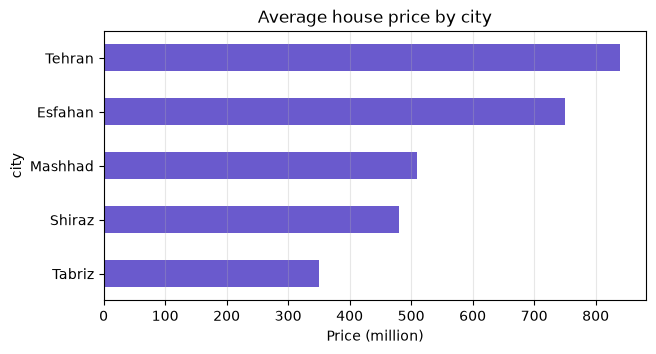

In [11]:
city_summary['average_price'].sort_values().plot(
    kind='barh',
    figsize=(7, 3.5),
    color='slateblue',
    title='Average house price by city',
    xlabel='Price (million)'
)
plt.grid(axis='x', alpha=0.3)
plt.show()

## Key Takeaways

- Use `head()`, `info()`, and `describe()` to inspect data.
- Use Boolean indexing to filter rows. - Use `isna()`, `fillna()`, and `drop_duplicates()` for basic cleaning.
- Use `groupby()` and `agg()` to calculate metrics.
- Visualize aggregated results to support data-driven decisions.